In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman
kalman.set_debug(0)



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Calorimeter Shower Modelling with Kalman Filters

This notebook builds a generic calorimeter model. It does not need ROOT.

The notebook follows three steps:
1. Define a detector as a stack of named material layers.
2. Simulate an EM (electromagnetic, gamma) shower or a hadronic (neutral) shower with a Monte Carlo sampler.
3. Reconstruct the shower path and energy with a 5-state Kalman filter.

**Plots in this notebook:**
- Side view (z-y): shows the detector geometry. Active pads appear in red.
- Hit projections: z-x and z-y scatter plots, plus an x-y pad energy map.
- Resolution curves.

---


## Step 1 — Material Library

The material library is a built-in database. For each material, it stores three properties:
- Radiation length (X0)
- Nuclear interaction length (lambda)
- Sampling resolution (sigma_s)

Active scintillator pads (`scint`, `scint_tile`) appear in red in every plot.


In [2]:
from kalman.apps.calorimeter import (
    MATERIALS, MATERIAL_COLORS,
    CaloLayer, CalorimeterGeometry, CalorimeterSampler,
    CalorimeterElectromagneticModel, CalorimeterHadronicModel,
    build_measurements, em_shower_profile, hadronic_shower_profile,
    moliere_radius_mm, ECAL_PRESETS, HCAL_PRESETS,
)

header = f"{'Key':<12} {'Label':<16} {'X0 [mm]':>9} {'lam [mm]':>10} {'sigma_s':>9} {'R_M [mm]':>10}"
print(header)
print("-" * len(header))
for key, mat in MATERIALS.items():
    sigma_s = mat["sigma_s"]
    moliere_radius = moliere_radius_mm(key)
    print(f"{key:<12} {mat['label']:<16} {mat['X0_mm']:>9.1f} "
          f"{mat['lambda_int_mm']:>10.1f} {str(round(sigma_s,3)) if sigma_s else '—':>9} {moliere_radius:>10.1f}")


Key          Label              X0 [mm]   lam [mm]   sigma_s   R_M [mm]
-----------------------------------------------------------------------
lyso         LYSO                  11.4      210.0      0.02       24.2
pwo          PbWO₄                  8.9      200.0     0.015       21.0
wsi          W/Si                   3.5       96.0     0.015        9.3
pb           Lead                   5.6      194.0         —       17.0
fe           Iron                  17.6      168.0         —       17.0
w            Tungsten               3.5       96.0         —        9.3
cu           Copper                14.4      153.0         —       16.1
scint        Scintillator         400.0      700.0       0.1      106.0
scint_tile   SiPM-on-Tile         400.0      700.0       0.5      106.0
si           Silicon               93.7      465.0      0.05       49.7
air          Air               304000.0   749000.0         —    75821.2


## Step 2 — ZDC-Style HCAL Geometry (Fe + SiPM-on-Tile)

HCAL means hadronic calorimeter. This design follows the ePIC ZDC design (arXiv:2406.12877).

- **Absorber**: iron, 20 mm per layer.
- **Active layer**: SiPM-on-tile scintillator pads. Each pad is 3 mm thick, about 53 mm wide, with an area of about 25 cm².
- **Layer count**: 40 absorber layers and 40 readout layers. This gives about 5 nuclear interaction lengths (lambda_int) of depth.

Active pads appear in red in the side view.


In [3]:
# ZDC HCAL: Fe absorber + SiPM-on-tile scintillator pads
hcal_layers = []
for _ in range(40):
    hcal_layers.append(CaloLayer("fe",          20., is_active=False))
    hcal_layers.append(CaloLayer("scint_tile",   3., is_active=True,
                                  cell_size_mm=53., sigma_sampling=0.50))

hcal = CalorimeterGeometry(hcal_layers, z_start=0., aperture_mm=600.)
print(hcal.summary())
print(f"\nPad position resolution (sigma): {hcal._active_layers[0].pos_resolution_mm:.1f} mm per layer")


CalorimeterGeometry
  Layers : 80 total, 40 active
  z range: 0 – 920 mm
  Depth  : 45.8 X₀,  4.93 λ_int
  X₀ eff : 20.1 mm/X₀   λ eff: 186.5 mm/λ
  Molière : 106.0 mm
  σ_s (EM): 0.500  σ_s (had): 0.50

Pad position resolution (sigma): 15.3 mm per layer


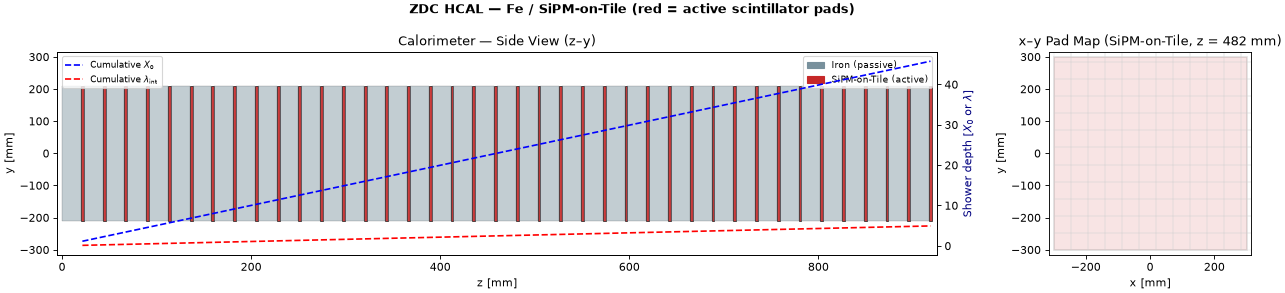

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8),
                          gridspec_kw={"width_ratios": [4, 1]})
hcal.plot_z(axes[0], show_depth=True)
hcal.plot_xy(axes[1])
fig.suptitle("ZDC HCAL — Fe / SiPM-on-Tile (red = active scintillator pads)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Step 3 — ECAL Geometry

ECAL means electromagnetic calorimeter. This notebook offers two ECAL designs:

- **Crystal ECAL**: 25 PbWO4 crystals, 23 mm each. Each crystal is about 2.6 radiation lengths (X0).
- **Pb/Scint sampling ECAL**: 25 layer pairs. Each pair has 2 mm of lead and 3 mm of scintillator.


In [5]:
# Crystal ECAL
ecal_crystal = CalorimeterGeometry(
    [CaloLayer("pwo", 23., is_active=True, cell_size_mm=22.)] * 25,
    z_start=700., aperture_mm=200.,
)

# Pb/Scint sampling ECAL (pads in red)
ecal_sampling_layers = []
for _ in range(25):
    ecal_sampling_layers.append(CaloLayer("pb",    2., is_active=False))
    ecal_sampling_layers.append(CaloLayer("scint", 3., is_active=True,
                                           cell_size_mm=10., sigma_sampling=0.20))
ecal_sampling = CalorimeterGeometry(ecal_sampling_layers, z_start=700., aperture_mm=200.)

ecal = ecal_crystal   # switch here
print(ecal.summary())


CalorimeterGeometry
  Layers : 25 total, 25 active
  z range: 700 – 1275 mm
  Depth  : 64.6 X₀,  2.88 λ_int
  X₀ eff : 8.9 mm/X₀   λ eff: 200.0 mm/λ
  Molière : 21.0 mm
  σ_s (EM): 0.015  σ_s (had): 0.50


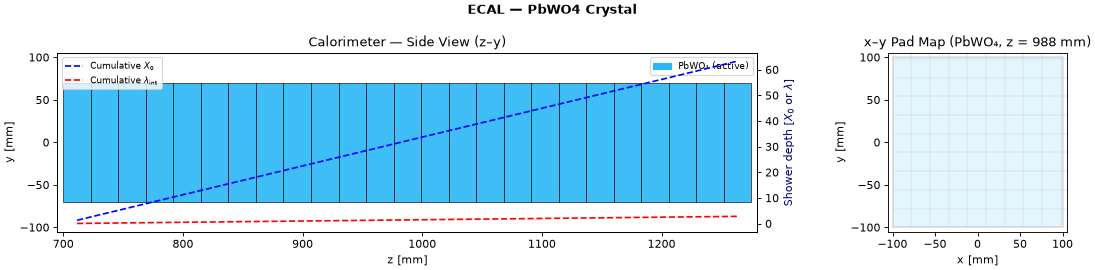

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5),
                          gridspec_kw={"width_ratios": [3, 1]})
ecal.plot_z(axes[0], show_depth=True)
ecal.plot_xy(axes[1])
fig.suptitle("ECAL — PbWO4 Crystal", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Step 4 — Combined ECAL + HCAL Side View

This view stacks the ECAL in front of the HCAL, in beam order.


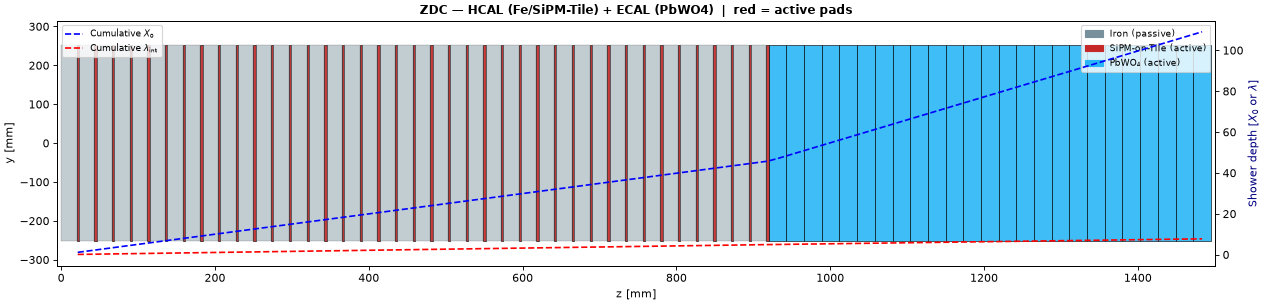

In [7]:
combined = CalorimeterGeometry(
    list(hcal._layers) + list(ecal._layers),
    z_start=0., aperture_mm=600.,
)
fig, ax = plt.subplots(figsize=(16, 4))
combined.plot_z(ax, show_depth=True, height_frac=0.42)
ax.set_title("ZDC — HCAL (Fe/SiPM-Tile) + ECAL (PbWO4)  |  red = active pads",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


## Step 5 — EM Shower (Gamma): Simulation and Hit Projections

`CalorimeterSampler.sample()` generates hits at the cell level. It uses the Longo-Sestili shower profile. The sampler assigns each hit to one pad, snapped to the cell grid.


In [8]:
E_gamma = 10.0  # GeV

# Beam: 20 mm offset in x, -15 mm in y; 50 mrad tilt in x, 30 mrad in y
x0_em, y0_em = 20., -15.   # entry position [mm]
tx_em, ty_em = 0.05,  0.03  # slopes [mm/mm] = [rad]

hits_em = CalorimeterSampler(ecal).sample(
    E_gamma, "gamma",
    x0=x0_em, y0=y0_em, tx=tx_em, ty=ty_em,
    seed=42)
print(f"Generated {len(hits_em)} hits for {E_gamma} GeV gamma")
print(f"Entry position : x={x0_em} mm, y={y0_em} mm")
print(f"Track slopes   : tx={tx_em} rad, ty={ty_em} rad")
print(f"Total deposited energy: {sum(h['E'] for h in hits_em):.3f} GeV")


Generated 138 hits for 10.0 GeV gamma
Entry position : x=20.0 mm, y=-15.0 mm
Track slopes   : tx=0.05 rad, ty=0.03 rad
Total deposited energy: 9.972 GeV


In [9]:
# --- Kalman reconstruction first (for track overlay) ---
z_em, R_em, meas_em = build_measurements(hits_em)

em_model = CalorimeterElectromagneticModel.from_geometry(0, hits_em, ecal)
em_model.engine.forward(meas_em)
em_model.engine.backward()
res_em = em_model.extract_smoothed()

print("EM reconstruction:")
print(f"  E = {res_em['E']:.3f} GeV  (true {E_gamma:.1f})")
print(f"  x0 = {res_em['x0']:+.2f} mm,  y0 = {res_em['y0']:+.2f} mm")
print(f"  chi2/dof = {res_em['chi2_dof']:.2f}")


EM reconstruction:
  E = 9.983 GeV  (true 10.0)
  x0 = +21.31 mm,  y0 = -13.57 mm
  chi2/dof = 2359.83


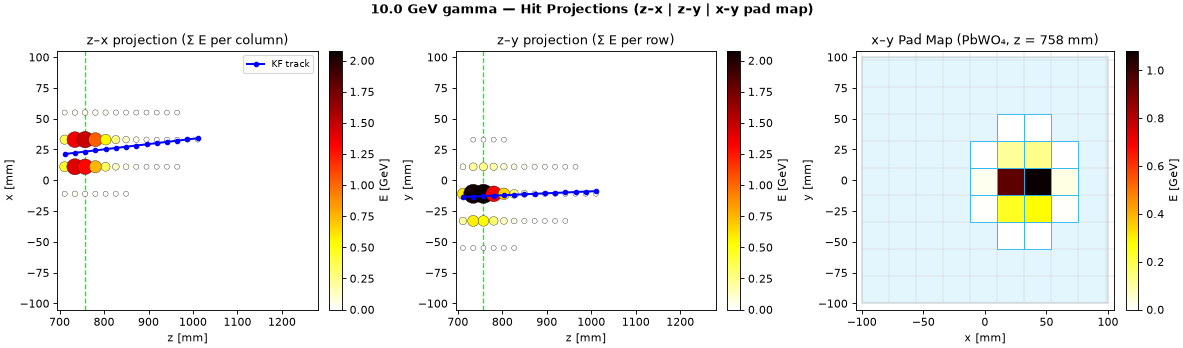

In [10]:
# --- Three-panel hit projections with KF track overlay ---
fig, axes = ecal.plot_hits_projections(
    hits_em,
    particle=f"{E_gamma} GeV gamma",
    smoothed_states=em_model.engine.smooth,
)
plt.show()


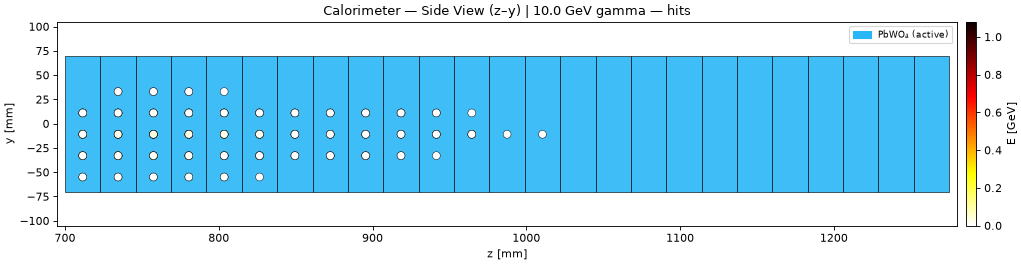

In [11]:
# --- Side view with hits overlaid ---
fig, ax = plt.subplots(figsize=(13, 3.5))
ecal.plot_z(ax, show_depth=False, hits=hits_em, particle=f"{E_gamma} GeV gamma")
plt.tight_layout()
plt.show()


## Step 6 — Hadronic Shower (Neutral): Simulation and Hit Projections

Neutrons and other neutral hadrons shower over many nuclear interaction lengths (lambda_int is about 186 mm effective). This makes the hadronic shower wider and longer than an EM shower.

Each red mark on the HCAL plot shows one hit. Larger marks show more deposited energy.


In [12]:
E_neutral = 10.0  # GeV

# Beam: -10 mm offset in x, +30 mm in y; -20 mrad tilt in x, 40 mrad in y
x0_had, y0_had = -10.,  30.   # entry position [mm]
tx_had, ty_had = -0.02,  0.04  # slopes [mm/mm] = [rad]

hits_had = CalorimeterSampler(hcal).sample(
    E_neutral, "neutral",
    x0=x0_had, y0=y0_had, tx=tx_had, ty=ty_had,
    seed=7)
print(f"Generated {len(hits_had)} hits for {E_neutral} GeV neutral")
print(f"Entry position : x={x0_had} mm, y={y0_had} mm")
print(f"Track slopes   : tx={tx_had} rad, ty={ty_had} rad")
print(f"Total deposited energy: {sum(h['E'] for h in hits_had):.3f} GeV")
print(f"Hadronic transverse spread: {hcal.hadronic_spread_mm:.1f} mm  (cf. lambda_eff/10)")


Generated 715 hits for 10.0 GeV neutral
Entry position : x=-10.0 mm, y=30.0 mm
Track slopes   : tx=-0.02 rad, ty=0.04 rad
Total deposited energy: 8.525 GeV
Hadronic transverse spread: 43.5 mm  (cf. lambda_eff/10)


In [13]:
# --- Kalman reconstruction ---
z_h, R_h, meas_h = build_measurements(hits_had)

had_model = CalorimeterHadronicModel.from_geometry(0, hits_had, hcal)
had_model.engine.forward(meas_h)
had_model.engine.backward()
res_h = had_model.extract_smoothed()

print("Hadronic reconstruction:")
print(f"  E = {res_h['E']:.3f} GeV  (true {E_neutral:.1f})")
print(f"  x0 = {res_h['x0']:+.2f} mm,  y0 = {res_h['y0']:+.2f} mm")
print(f"  chi2/dof = {res_h['chi2_dof']:.2f}")


Hadronic reconstruction:
  E = 8.524 GeV  (true 10.0)
  x0 = -10.51 mm,  y0 = +31.05 mm
  chi2/dof = 0.14


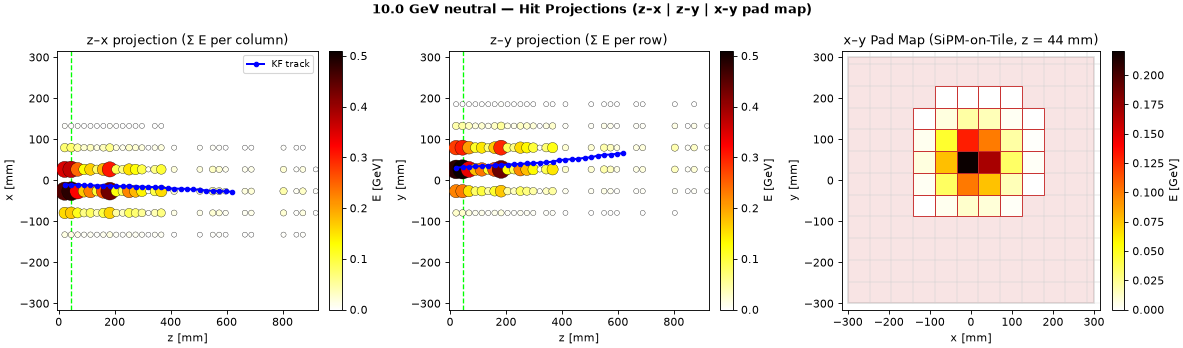

In [14]:
# --- Three-panel projections ---
fig, axes = hcal.plot_hits_projections(
    hits_had,
    particle=f"{E_neutral} GeV neutral",
    smoothed_states=had_model.engine.smooth,
)
plt.show()


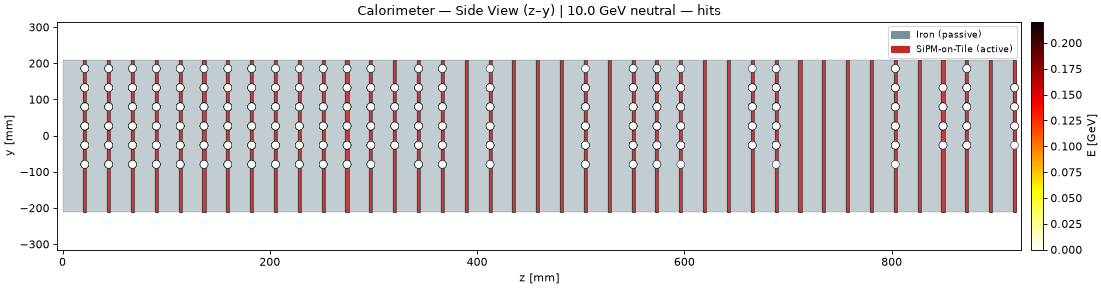

In [15]:
# --- HCAL side view with hits ---
fig, ax = plt.subplots(figsize=(14, 3.8))
hcal.plot_z(ax, show_depth=False, hits=hits_had, particle=f"{E_neutral} GeV neutral")
plt.tight_layout()
plt.show()


## Step 7 — Resolution Study

The theoretical sampling resolution is sigma_E/E = sigma_s / sqrt(E).

This step compares that resolution to the ePIC ZDC requirements:
- HCAL: 50%/sqrt(E)
- ECAL: 20%/sqrt(E)


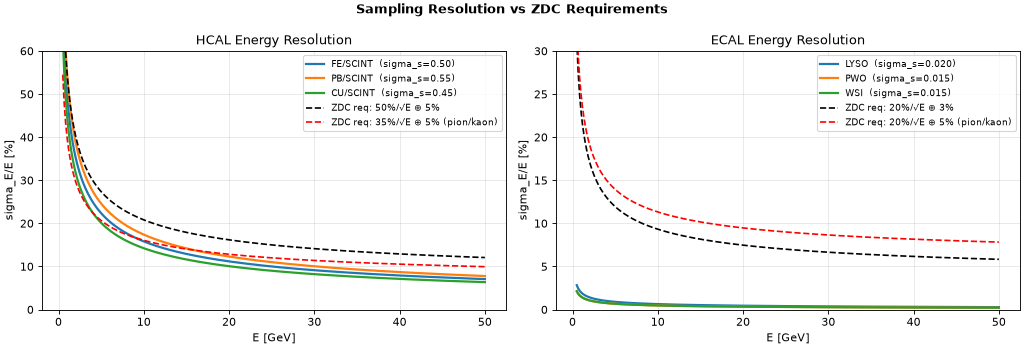

In [16]:
energies = np.linspace(0.5, 50., 300)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# HCAL
ax = axes[0]
ax.set_title("HCAL Energy Resolution")
for name, preset in HCAL_PRESETS.items():
    sigma_s = preset["sigma_sampling"]
    ax.plot(energies, 100 * sigma_s / np.sqrt(energies), lw=2,
            label=f"{name.replace('_','/').upper()}  (sigma_s={sigma_s:.2f})")
# ZDC requirement: 50%/sqrt(E) + 5% (spectator neutrons)
ax.plot(energies, 50/np.sqrt(energies) + 5, "k--", lw=1.5,
        label="ZDC req: 50%/√E ⊕ 5%")
# ZDC requirement: 35%/sqrt(E) + 3-5% (pion/kaon)
ax.plot(energies, 35/np.sqrt(energies) + 5, "r--", lw=1.5,
        label="ZDC req: 35%/√E ⊕ 5% (pion/kaon)")
ax.set_xlabel("E [GeV]")
ax.set_ylabel("sigma_E/E [%]")
ax.set_ylim(0, 60)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# ECAL
ax2 = axes[1]
ax2.set_title("ECAL Energy Resolution")
for name, preset in ECAL_PRESETS.items():
    sigma_s = preset["sigma_sampling"]
    ax2.plot(energies, 100 * sigma_s / np.sqrt(energies), lw=2,
             label=f"{name.upper()}  (sigma_s={sigma_s:.3f})")
# ZDC requirement: 20%/sqrt(E) + 3% (u-channel)
ax2.plot(energies, 20/np.sqrt(energies) + 3, "k--", lw=1.5,
         label="ZDC req: 20%/√E ⊕ 3%")
ax2.plot(energies, 20/np.sqrt(energies) + 5, "r--", lw=1.5,
         label="ZDC req: 20%/√E ⊕ 5% (pion/kaon)")
ax2.set_xlabel("E [GeV]")
ax2.set_ylabel("sigma_E/E [%]")
ax2.set_ylim(0, 30)
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.suptitle("Sampling Resolution vs ZDC Requirements", fontweight="bold")
plt.tight_layout()
plt.show()


## Step 8 — Monte Carlo Resolution Scan

This step simulates many events at several energies. It measures the energy resolution of the Kalman filter's reconstructed energy.


In [17]:
import numpy as np

energies_scan = [2., 5., 10., 20., 50.]
n_trials = 30

results_em  = {}
results_had = {}

for E in energies_scan:
    e_reco_em, e_reco_had = [], []
    for seed in range(n_trials):
        # EM (gamma) shower
        hits_gamma = CalorimeterSampler(ecal).sample(E, "gamma", seed=seed)
        if hits_gamma:
            _, _, meas_gamma = build_measurements(hits_gamma)
            model_em = CalorimeterElectromagneticModel.from_geometry(0, hits_gamma, ecal)
            model_em.engine.forward(meas_gamma)
            model_em.engine.backward()
            e_reco_em.append(model_em.extract_smoothed()["E"])
        # Hadronic (neutral) shower
        hits_neutral = CalorimeterSampler(hcal).sample(E, "neutral", seed=seed)
        if hits_neutral:
            _, _, meas_neutral = build_measurements(hits_neutral)
            model_had = CalorimeterHadronicModel.from_geometry(0, hits_neutral, hcal)
            model_had.engine.forward(meas_neutral)
            model_had.engine.backward()
            e_reco_had.append(model_had.extract_smoothed()["E"])
    results_em[E]  = (np.mean(e_reco_em),  np.std(e_reco_em))
    results_had[E] = (np.mean(e_reco_had), np.std(e_reco_had))
    print(f"E={E:4.0f} GeV | EM: {results_em[E][0]:.2f}±{results_em[E][1]:.2f} GeV"
          f"  | HAD: {results_had[E][0]:.2f}±{results_had[E][1]:.2f} GeV")


E=   2 GeV | EM: 2.00±0.02 GeV  | HAD: 2.68±0.50 GeV
E=   5 GeV | EM: 5.00±0.03 GeV  | HAD: 5.69±0.83 GeV


E=  10 GeV | EM: 10.00±0.05 GeV  | HAD: 10.60±1.18 GeV
E=  20 GeV | EM: 19.99±0.07 GeV  | HAD: 20.39±1.69 GeV


E=  50 GeV | EM: 49.99±0.10 GeV  | HAD: 50.01±2.78 GeV


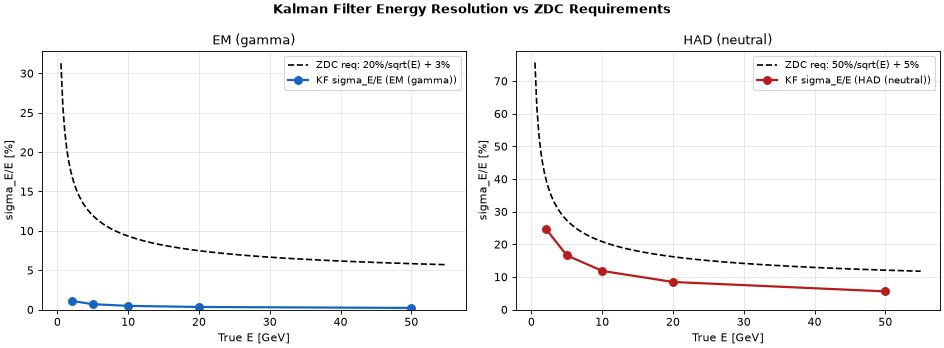

In [18]:
E_arr = np.array(energies_scan)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, results, label, color, req_s, req_c in [
    (axes[0], results_em,  "EM (gamma)",   "#1565C0", 0.20, 3.),
    (axes[1], results_had, "HAD (neutral)","#B71C1C", 0.50, 5.),
]:
    means = np.array([results[E][0] for E in energies_scan])
    stds  = np.array([results[E][1] for E in energies_scan])

    ax.errorbar(E_arr, stds / E_arr * 100, fmt="o-", color=color,
                lw=2, ms=7, label=f"KF sigma_E/E ({label})")

    e_fine = np.linspace(0.5, 55., 200)
    ax.plot(e_fine, req_s * 100 / np.sqrt(e_fine) + req_c, "k--", lw=1.5,
            label=f"ZDC req: {int(req_s*100)}%/sqrt(E) + {req_c:.0f}%")

    ax.set_xlabel("True E [GeV]")
    ax.set_ylabel("sigma_E/E [%]")
    ax.set_title(label)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0)

plt.suptitle("Kalman Filter Energy Resolution vs ZDC Requirements",
             fontweight="bold")
plt.tight_layout()
plt.show()


## Step 9 — Custom Geometry (W/Si ECAL + Fe/SiPM-Tile HCAL)

Build any detector configuration with this framework. This example places a compact W/Si ECAL (EIC-style) in front of the Fe/SiPM-tile HCAL.


CalorimeterGeometry
  Layers : 140 total, 70 active
  z range: 0 – 1034 mm
  Depth  : 75.9 X₀,  6.05 λ_int
  X₀ eff : 13.6 mm/X₀   λ eff: 171.0 mm/λ
  Molière : 81.9 mm
  σ_s (EM): 0.292  σ_s (had): 0.50


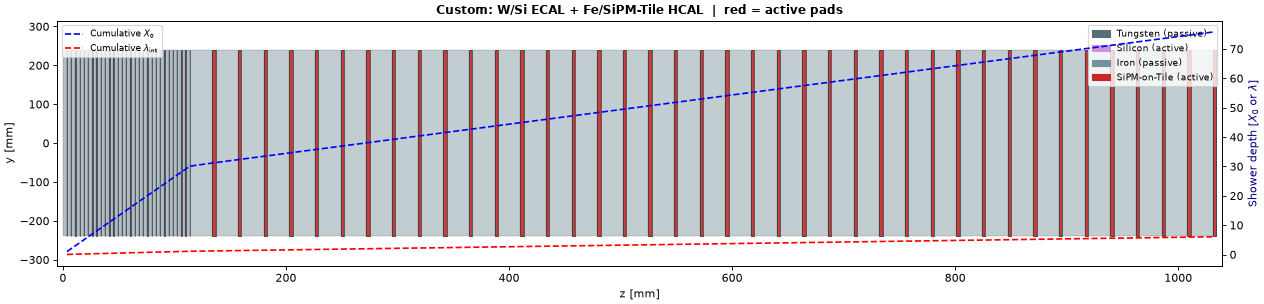

In [19]:
wsi_layers = []
for _ in range(30):
    wsi_layers.append(CaloLayer("w",   3.5, is_active=False))
    wsi_layers.append(CaloLayer("si",  0.3, is_active=True,
                                 cell_size_mm=5., sigma_sampling=0.015))

# Reuse the Fe/SiPM-tile HCAL layers already built for `hcal` above.
custom = CalorimeterGeometry(wsi_layers + hcal_layers, z_start=0., aperture_mm=600.)
print(custom.summary())

fig, ax = plt.subplots(figsize=(16, 4))
custom.plot_z(ax, show_depth=True, height_frac=0.40)
ax.set_title("Custom: W/Si ECAL + Fe/SiPM-Tile HCAL  |  red = active pads",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()
